# Hands-on: Color Space, Thresholding, dan Background Replacement
### Study group IMV Laboratory.

Modul praktikum ini membahas konsep dan implementasi pemrosesan citra digital untuk segmentasi warna (*chroma keying*) menggunakan Python dan OpenCV. Praktikan akan mempelajari cara mengisolasi objek berdasarkan ruang warna HSV, membuat mask biner, dan menggabungkan subjek ke latar belakang baru secara presisi.

---

### Alur Pembelajaran:
1. **Pengenalan OpenCV & Akuisisi Citra**: Membaca frame dari webcam (`cv2.VideoCapture`), memahami representasi array citra, serta mekanisme fallback citra sintetis jika webcam tidak terdeteksi.
2. **Eksplorasi Color Space**: Membedah perbedaan representasi BGR vs RGB vs HSV, serta memvisualisasikan channel Hue (H), Saturation (S), dan Value (V).
3. **Thresholding (Pemisahan Objek)**: Membandingkan keterbatasan Binary Thresholding pada grayscale (`cv2.threshold`) dengan Color Range Thresholding pada HSV (`cv2.inRange`).
4. **Masking & Operasi Bitwise**: Memahami prinsip gerbang biner dan menerapkan `cv2.bitwise_not` serta `cv2.bitwise_and` untuk memisahkan subjek dari background.
5. **Background Replacement & Real-time Live Chroma Key**: Menggabungkan subjek ke background baru menggunakan `cv2.add`, serta template script webcam interaktif real-time.
6. **Latihan Praktikan**: Tantangan aplikatif mandiri untuk menguji pemahaman materi.

---

### Library yang Dipakai:
- **`numpy`**: Manipulasi array matriks citra dan pembuatan batas warna (*lower* dan *upper bound*).
- **`opencv-python` (`cv2`)**: Akuisisi webcam, konversi ruang warna (`cvtColor`), thresholding (`threshold`, `inRange`), dan operasi bitwise (`bitwise_and`, `bitwise_not`, `add`).
- **`matplotlib`**: Menampilkan plot gambar dan perbandingan tahapan proses.

```bash
# Perintah instalasi library jika belum terpasang di environment Anda:
pip install numpy opencv-python matplotlib
```

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Konfigurasi resolusi plot matplotlib agar tampilan visualisasi tajam dan jelas
plt.rcParams['figure.dpi'] = 100

## 0. Persiapan: Fungsi Bantu, Akuisisi Webcam, dan Gambar Background

### Representasi Citra pada OpenCV:
- **Urutan Channel BGR:** Secara default, OpenCV membaca citra dalam urutan channel **BGR (Blue, Green, Red)**, bukan RGB. Citra disimpan di memori sebagai array `numpy.ndarray` bertipe `uint8` dengan rentang nilai $0 - 255$. Jika citra BGR langsung ditampilkan dengan pustaka Matplotlib (yang mengasumsikan urutan RGB), warna akan tampak terbalik (warna kulit menjadi kebiruan dan warna merah tertukar dengan warna biru).
- **Alur Kerja Bagian Ini:**
  1. Praktikan mengambil $1$ frame dari webcam menggunakan `cv2.VideoCapture(0)` dengan posisi subjek berada di depan latar belakang satu warna (misal kain hijau/green screen atau biru).
  2. Menyiapkan $1$ berkas gambar background pengganti (`background.jpg`).
  3. **Mekanisme Fallback Otomatis:** Jika webcam tidak terdeteksi saat eksekusi atau file `background.jpg` belum disiapkan, kode otomatis membangkitkan citra dummy sintetis berukuran $480 \times 640$ (subjek simulasi di depan background hijau pekat + background pemandangan buatan). Dengan mekanisme ini, seluruh sel di bawahnya dijamin **100% reproducible** dan dapat dijalankan tanpa error di perangkat apa pun.

[INFO] Berhasil mengambil 1 frame dari webcam.
[INFO] File 'background.jpg' tidak ditemukan. Membuat gambar background pemandangan sintetis...
frame.shape : (480, 640, 3)
frame.dtype : uint8
frame.min() : 0
frame.max() : 255


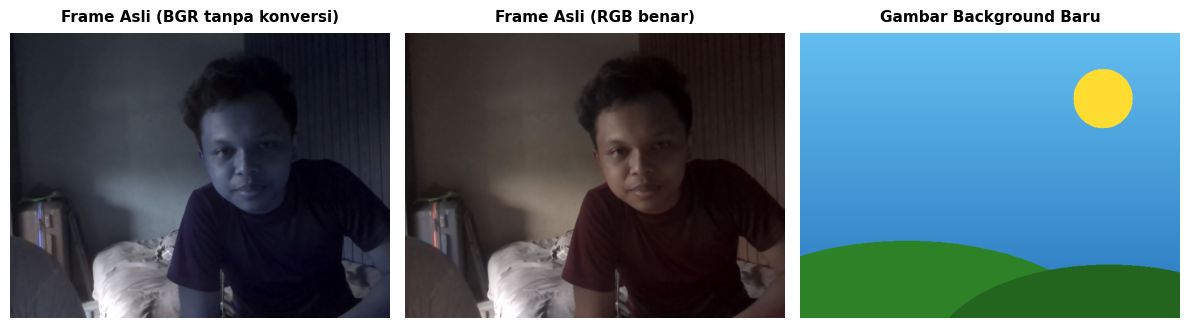

In [7]:
def show(images, titles, cols=3, size=(4, 4)):
    """
    Fungsi bantu untuk menampilkan kumpulan gambar berdampingan menggunakan matplotlib.pyplot.
    Mendukung tampilan citra RGB (3 channel) maupun Grayscale/Mask (2 channel dengan cmap='gray', vmin=0, vmax=255).
    """
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size[0], rows * size[1]))
    
    # Ratakan axes menjadi array 1D agar konsisten saat diiterasi
    if n == 1:
        axes = np.array([axes])
    else:
        axes = np.array(axes).flatten()
        
    for i in range(n):
        img = images[i]
        title = titles[i] if i < len(titles) else ""
        ax = axes[i]
        
        # Deteksi dimensi gambar: 2 channel (Grayscale/Mask) atau 3 channel (RGB)
        if img.ndim == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(img)
            
        ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
        ax.axis('off')
        
    # Sembunyikan subplot sisa yang tidak terpakai
    for j in range(n, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 1. Akuisisi 1 Frame dari Webcam (dengan Fallback Citra Sintetis)
# ==============================================================================
cap = cv2.VideoCapture(0)
frame = None

if cap.isOpened():
    ret, captured_frame = cap.read()
    if ret and captured_frame is not None:
        frame = captured_frame
    cap.release()

# Fallback: Buat citra sintetis berukuran (480, 640, 3) bertipe uint8 jika webcam gagal/None
if frame is None:
    print("[INFO] Webcam tidak terdeteksi / gagal diakses. Menggunakan citra sintetis subjek...")
    frame = np.zeros((480, 640, 3), dtype=np.uint8)
    # Latar hijau green screen (BGR: B=0, G=200, R=0)
    frame[:] = [0, 200, 0]
    
    # Objek simulasi subjek di tengah frame
    # Badan / baju biru (BGR: B=180, G=50, R=50)
    cv2.ellipse(frame, (320, 440), (140, 160), 0, 180, 360, (180, 50, 50), -1)
    # Wajah / warna kulit (BGR: B=140, G=180, R=235)
    cv2.circle(frame, (320, 230), 80, (140, 180, 235), -1)
    # Rambut hitam
    cv2.ellipse(frame, (320, 180), (82, 50), 0, 180, 360, (20, 20, 20), -1)
    # Mata dan senyum
    cv2.circle(frame, (290, 220), 8, (255, 255, 255), -1)
    cv2.circle(frame, (290, 220), 4, (20, 20, 20), -1)
    cv2.circle(frame, (350, 220), 8, (255, 255, 255), -1)
    cv2.circle(frame, (350, 220), 4, (20, 20, 20), -1)
    cv2.ellipse(frame, (320, 260), (30, 15), 0, 0, 180, (40, 40, 200), -1)
else:
    print("[INFO] Berhasil mengambil 1 frame dari webcam.")

# ==============================================================================
# 2. Persiapan Gambar Background Pengganti (dengan Fallback Sintetis)
# ==============================================================================
bg_path = 'background.jpg'
bg_img = cv2.imread(bg_path)

if bg_img is not None:
    print(f"[INFO] Membaca gambar background dari '{bg_path}'.")
    bg_img = cv2.resize(bg_img, (frame.shape[1], frame.shape[0]))
else:
    print(f"[INFO] File '{bg_path}' tidak ditemukan. Membuat gambar background pemandangan sintetis...")
    h, w = frame.shape[:2]
    bg_img = np.zeros((h, w, 3), dtype=np.uint8)
    # Gradasi langit biru cerah (BGR)
    for y in range(h):
        ratio = y / h
        bg_img[y, :] = [int(240 - 50 * ratio), int(190 - 70 * ratio), int(100 - 60 * ratio)]
    # Matahari kuning cerah
    cv2.circle(bg_img, (510, 110), 50, (50, 220, 255), -1)
    # Bukit pemandangan hijau
    cv2.ellipse(bg_img, (180, 520), (340, 170), 0, 0, 360, (40, 130, 45), -1)
    cv2.ellipse(bg_img, (520, 550), (300, 160), 0, 0, 360, (30, 100, 35), -1)

# Konversi BGR ke RGB untuk keperluan visualisasi matplotlib
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
bg_rgb = cv2.cvtColor(bg_img, cv2.COLOR_BGR2RGB)

# Cetak metadata matriks citra frame
print(f"frame.shape : {frame.shape}")
print(f"frame.dtype : {frame.dtype}")
print(f"frame.min() : {frame.min()}")
print(f"frame.max() : {frame.max()}")

# Tampilkan visualisasi perbandingan
show(
    [frame, frame_rgb, bg_rgb],
    [
        "Frame Asli (BGR tanpa konversi)",
        "Frame Asli (RGB benar)",
        "Gambar Background Baru"
    ],
    cols=3,
    size=(4, 4)
)

## 1. Color Space: RGB vs HSV

### Kelemahan Ruang Warna RGB/BGR untuk Segmentasi Warna:
- Pada ruang warna RGB/BGR, setiap warna dibentuk oleh kombinasi tiga channel: **Red**, **Green**, dan **Blue**.
- **Masalah mendasar:** Informasi **warna murni (kromatisitas)** dan **intensitas cahaya (luminans/kecerahan)** saling bercampur di seluruh channel R, G, dan B.
- Jika intensitas pencahayaan di ruangan berubah sedikit saja (misalnya muncul bayangan tubuh pada layar hijau atau perubahan sudut lampu), nilai ketiga channel R, G, dan B akan berubah serentak secara signifikan. Hal ini membuat penetapan ambang batas segmentasi (*thresholding*) pada ruang RGB menjadi sangat tidak stabil dan rentan gagal.

---

### Ruang Warna HSV (Hue, Saturation, Value):
Ruang warna HSV memisahkan komponen warna dari tingkat pencahayaan, menyerupai cara manusia mendeskripsikan warna. Di OpenCV dengan tipe data `uint8`, ketiga channel memiliki rentang nilai sebagai berikut:

- **Hue (H) — Jenis Warna Dasar:**
  - Menyatakan corak warna murni pada roda spektrum warna lingkaran ($0^{\circ} - 360^{\circ}$).
  - Di OpenCV, karena nilai `uint8` dibatasi hingga 255, rentang derajat dibagi dua menjadi **`0 - 179`**.
  - *Perkiraan nilai Hue di OpenCV:* Merah (`0 - 10` dan `170 - 179`), Kuning (`20 - 35`), **Hijau (`35 - 85`)**, Biru (`90 - 130`).
- **Saturation (S) — Kepekatan / Kemurnian Warna:**
  - Menyatakan seberapa jenuh warna tersebut, dari warna pudar/abu-abu ke warna murni pekat.
  - Rentang di OpenCV: **`0 - 255`**.
- **Value (V) — Kecerahan Cahaya (Brightness):**
  - Menyatakan intensitas cahaya dari gelap gulita/hitam hingga terang benderang.
  - Rentang di OpenCV: **`0 - 255`**.

> **Keuntungan Utama:** Untuk mengisolasi latar belakang hijau, kita cukup mengunci nilai pada channel **Hue**, sementara channel **Saturation** dan **Value** dapat diberi rentang batas toleransi yang lebar sehingga segmentasi tetap konsisten meskipun terdapat variasi bayangan pencahayaan.

In [ ]:
# Konversi citra frame dari BGR ke HSV
frame_hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

# Pisahkan masing-masing channel Hue, Saturation, dan Value
h_channel, s_channel, v_channel = cv2.split(frame_hsv)

# Visualisasikan citra asli (RGB) bersama masing-masing channel HSV
# Channel H, S, dan V adalah matriks 2D sehingga otomatis dirender dengan cmap='gray'
show(
    [frame_rgb, h_channel, s_channel, v_channel],
    [
        "Gambar Asli (RGB)",
        "Channel Hue (H)",
        "Channel Saturation (S)",
        "Channel Value (V)"
    ],
    cols=4,
    size=(4, 4)
)

## 2. Thresholding: Binary Threshold vs HSV Range Thresholding

### Konsep Dasar Thresholding:
Thresholding adalah teknik segmentasi paling mendasar yang mengubah citra bergradasi kontinu menjadi citra biner (hanya bernilai `0` untuk hitam dan `255` untuk putih). Citra biner inilah yang berfungsi sebagai **mask** (stensil) pemisah antara objek yang diinginkan dan latar belakang yang ingin diganti.

---

### Perbandingan Metode:

- **`cv2.threshold()` (Binary Thresholding pada Citra Grayscale):**
  - Hanya bekerja pada $1$ channel (citra grayscale).
  - Citra grayscale hanya merepresentasikan intensitas kecerahan total:
    $$Y = 0.299R + 0.587G + 0.114B$$
  - Dua warna yang berbeda sama sekali (misal warna kulit subjek dan warna kain hijau latar) bisa saja menghasilkan intensitas kecerahan abu-abu yang persis sama. Akibatnya, `cv2.threshold()` **gagal memisahkan warna spesifik latar belakang**.
- **`cv2.inRange(hsv, lower, upper)` (Color Range Thresholding pada Ruang Warna HSV):**
  - Bekerja pada $3$ channel (H, S, dan V) secara simultan.
  - Memeriksa apakah setiap piksel berada di dalam rentang `lower <= pixel <= upper`.
  - Jika berada dalam rentang pada seluruh channel, piksel dijadikan `255` (putih); jika tidak, dijadikan `0` (hitam).
  - **Sangat presisi dalam mengisolasi warna latar hijau green screen** tanpa terpengaruh oleh warna objek di sekitarnya.

In [ ]:
# 1. Binary Thresholding konvensional pada citra Grayscale
gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
_, binary_thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# 2. Color Range Thresholding pada HSV menggunakan cv2.inRange
# Definisikan rentang warna hijau (Green Screen):
# - Hue: 35 s.d. 85 (mencakup spektrum hijau muda, hijau daun, hingga hijau toska)
# - Saturation: 50 s.d. 255 (menyaring warna putih/abu-abu netral)
# - Value: 50 s.d. 255 (menyaring area bayangan yang terlalu gelap)
lower_green = np.array([35, 50, 50])
upper_green = np.array([85, 255, 255])

# Panduan penyesuaian jika menggunakan latar warna lain:
# - Latar Biru  : lower = np.array([90, 50, 50]),   upper = np.array([130, 255, 255])
# - Latar Merah : lower = np.array([0, 70, 50]),    upper = np.array([10, 255, 255])

# Buat mask biner: area hijau menjadi 255 (putih), area selain hijau menjadi 0 (hitam)
mask = cv2.inRange(frame_hsv, lower_green, upper_green)

# Tampilkan perbandingan ketiga hasil thresholding
show(
    [gray, binary_thresh, mask],
    [
        "Citra Grayscale",
        "Binary Threshold Biasa",
        "HSV Mask (cv2.inRange)"
    ],
    cols=3,
    size=(4, 4)
)

## 3. Masking & Operasi Bitwise

### Cara Kerja Matriks Mask Biner:
Matriks mask biner berfungsi sebagai stensil atau gerbang logika pada setiap piksel:
- **Piksel bernilai `255` (Putih / TRUE):** Meloloskan nilai piksel citra asli apa adanya.
- **Piksel bernilai `0` (Hitam / FALSE):** Menahan/menghapus piksel citra sehingga bernilai `0` (hitam pekat).

---

### Tahapan Pemotongan dengan Operasi Bitwise:
1. **`mask` (Mask Background):**
   - Area latar belakang lama bernilai `255` (putih) dan area subjek bernilai `0` (hitam).
   - Digunakan untuk memotong gambar background baru agar hanya muncul di area latar hijau.
2. **`mask_inv = cv2.bitwise_not(mask)` (Mask Inverse / Subjek):**
   - Membalik nilai biner ($255 - \text{mask}$) sehingga area subjek bernilai `255` (putih) dan area latar hijau bernilai `0` (hitam).
   - Digunakan untuk memotong subjek dari frame webcam.
3. **`cv2.bitwise_and(src, src, mask=...)`:**
   - Mengekstrak piksel gambar sesuai area putih pada mask yang ditentukan.

In [ ]:
# 1. Hitung mask inverse untuk mengisolasi subjek
mask_inv = cv2.bitwise_not(mask)

# 2. Ekstrak foreground (subjek) dari frame webcam
# Piksel subjek diloloskan, area green screen diubah menjadi hitam (0)
fg = cv2.bitwise_and(frame_rgb, frame_rgb, mask=mask_inv)

# 3. Ekstrak background baru sesuai bentuk area green screen
# Piksel background baru diloloskan pada posisi hijau, area subjek diubah menjadi hitam (0)
bg_cut = cv2.bitwise_and(bg_rgb, bg_rgb, mask=mask)

# Visualisasikan keempat matriks hasil proses masking
show(
    [mask, mask_inv, fg, bg_cut],
    [
        "Mask Background",
        "Mask Inverse (Subjek)",
        "Hasil Potong Foreground (fg)",
        "Hasil Potong Background (bg_cut)"
    ],
    cols=4,
    size=(4, 4)
)

## 4. Penggabungan Akhir (Background Replacement) & Real-time Webcam

### Penggabungan Matriks Citra:
Langkah terakhir dari pipeline Chroma Key adalah menjumlahkan matriks `fg` dan matriks `bg_cut` menggunakan operasi penambahan citra:
$$\text{Hasil Akhir} = \text{fg} + \text{bg\_cut}$$

- Pada matriks `fg`: area subjek berisi piksel subjek asli, sedangkan area latar bernilai `0` (hitam).
- Pada matriks `bg_cut`: area subjek bernilai `0` (hitam), sedangkan area latar berisi piksel gambar background baru.
- Penjumlahan piksel:
  - Pada area subjek: $\text{Piksel Subjek} + 0 = \text{Piksel Subjek}$
  - Pada area latar: $0 + \text{Piksel Background Baru} = \text{Piksel Background Baru}$
- Kita menggunakan fungsi **`cv2.add(fg, bg_cut)`** untuk menggabungkan kedua citra tersebut secara sempurna.

---

### Implementasi Real-time Webcam:
Di bawah ini disertakan fungsi `run_live_chroma_key()` yang mengimplementasikan seluruh pipeline di atas secara real-time frame-by-frame menggunakan loop `cv2.VideoCapture(0)` dan jendela interaktif `cv2.imshow()`. Praktikan dapat menjalankan fungsi ini secara langsung di lingkungan lokal (misal VSCode) dan menekan tombol `'q'` untuk keluar.

In [ ]:
# 1. Hitung hasil penggabungan akhir dengan cv2.add
final_result = cv2.add(fg, bg_cut)

# Tampilkan perbandingan akhir dengan show()
show(
    [frame_rgb, bg_rgb, final_result],
    [
        "Frame Asli Webcam",
        "Gambar Background Baru",
        "Hasil Akhir Background Replacement"
    ],
    cols=3,
    size=(5, 4)
)

# ==============================================================================
# 2. Template Fungsi Live Chroma Key Real-Time
# ==============================================================================
def run_live_chroma_key(bg_path='background.jpg', 
                        lower_hsv=np.array([35, 50, 50]), 
                        upper_hsv=np.array([85, 255, 255])):
    """
    Menjalankan background replacement (chroma key) secara real-time via webcam.
    Tekan tombol 'q' pada jendela tampilan OpenCV untuk keluar dari program.
    
    Catatan: Jalankan fungsi ini di lingkungan lokal (VSCode / Terminal lokal),
    karena cv2.imshow membutuhkan display GUI desktop.
    """
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("[ERROR] Webcam tidak dapat diakses.")
        return

    # Baca gambar background pengganti
    bg = cv2.imread(bg_path)

    print("[INFO] Live Chroma Key aktif. Tekan tombol 'q' di jendela window untuk berhenti.")
    
    while True:
        ret, live_frame = cap.read()
        if not ret:
            print("[WARNING] Gagal membaca frame dari webcam.")
            break

        h, w = live_frame.shape[:2]
        
        # Samakan ukuran background dengan frame webcam
        if bg is None or bg.shape[:2] != (h, w):
            if bg is not None:
                bg_resized = cv2.resize(bg, (w, h))
            else:
                # Background sintetis jika file background.jpg belum tersedia
                bg_resized = np.zeros((h, w, 3), dtype=np.uint8)
                bg_resized[:, :] = [240, 180, 100]  # Warna biru langit BGR
        else:
            bg_resized = bg

        # Pipeline Chroma Key:
        # 1. Konversi BGR ke HSV
        hsv = cv2.cvtColor(live_frame, cv2.COLOR_BGR2HSV)

        # 2. Thresholding warna background
        live_mask = cv2.inRange(hsv, lower_hsv, upper_hsv)

        # 3. Mask inverse untuk subjek
        live_mask_inv = cv2.bitwise_not(live_mask)

        # 4. Potong foreground dan background
        live_fg = cv2.bitwise_and(live_frame, live_frame, mask=live_mask_inv)
        live_bg_cut = cv2.bitwise_and(bg_resized, bg_resized, mask=live_mask)

        # 5. Gabungkan kedua potongan
        live_final = cv2.add(live_fg, live_bg_cut)

        # Tampilkan pada jendela OpenCV
        cv2.imshow("Live Chroma Key - IMV Laboratory (Tekan 'q' untuk keluar)", live_final)

        # Keluar dari loop jika tombol 'q' ditekan
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    # Bersihkan resource webcam dan window
    cap.release()
    cv2.destroyAllWindows()
    print("[INFO] Sesi Live Chroma Key selesai.")

# Contoh pemanggilan fungsi live webcam (diberi komentar agar tidak memblokir eksekusi sel):
# run_live_chroma_key('background.jpg')

## 5. Latihan Praktikan

Untuk memperdalam pemahaman dan keterampilan praktis, selesaikan 3 latihan aplikatif berikut:

1. **Latihan 1: Kalibrasi Warna Bebas (Blue Screen / Dinding Kamar)**
   - Ambil foto diri Anda via webcam di depan latar berwarna bebas selain hijau (misalnya dinding kamar berwarna biru, kain merah, atau pakaian tertentu).
   - Cari rentang nilai `[H, S, V]` warna tersebut dengan memeriksa nilai piksel (`frame_hsv[y, x]`).
   - Ubah nilai `lower_green` dan `upper_green` menjadi batas warna baru Anda, lalu buktikan bahwa background pengganti berhasil diterapkan secara rapi.

2. **Latihan 2: Reduksi Bintik Noise & Smoothing Masking**
   - Pada kondisi riil, pencahayaan yang tidak merata sering memicu kebocoran atau bintik-bintik noise (lubang kecil pada tubuh subjek atau bintik hitam pada background).
   - Eksplorasi penyesuaian batas `Saturation` dan `Value` pada `cv2.inRange`.
   - Terapkan teknik *smoothing* sederhana sebelum thresholding atau pada mask hasil thresholding, misalnya:
     ```python
     # Alternatif A: Blurring pada frame sebelum thresholding
     frame_blur = cv2.GaussianBlur(frame, (5, 5), 0)
     
     # Alternatif B: Median filter untuk menghilangkan salt-and-pepper noise pada mask
     clean_mask = cv2.medianBlur(mask, 5)
     ```
   - Amati bagaimana perbedaan kebersihan mask dan ketajaman tepi (*edge*) subjek setelah dihaluskan.

3. **Latihan 3: Logika Masking Terbalik (*Invisibility Cloak*)**
   - Balikkan logika masking (`mask` dan `mask_inv`): buatlah agar badan atau pakaian subjek yang berwarna tertentu justru digantikan oleh gambar pemandangan/background, sementara latar belakang ruangan tetap asli.
   - Perhatikan efek visual tembus pandang (*invisibility*) yang dihasilkan, mirip dengan efek jubah tembus pandang pada film fiksi ilmiah!